<a href="https://colab.research.google.com/github/fatimalunazzz/TPI.SYS/blob/main/TPI_SyS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TPI - HITO 3: Prototipo Funcional

Detección y Clasificación Automática de Latidos Ventriculares Ectópicos (VEB/PVC) mediante Procesamiento Digital de Señales de ECG


In [1]:
# Instalación de dependencias
!pip install wfdb scipy numpy matplotlib

### Configuración del Entorno e Ingesta de Datos

El primer paso de nuestro pipeline consiste en la adquisición de las señales biomédicas y sus respectivas validaciones clínicas. Utilizaremos la MIT-BIH Arrhythmia Database (PhysioNet).

1. Configuración del Entorno: Importación de las librerías de procesamiento matricial (`numpy`), visualización (`matplotlib`) y lectura de formatos biomédicos estándar (`wfdb`).
2. Conexión a la Base de Datos (Nube): Mediante el parámetro `pn_dir='mitdb'`, la librería se conecta a los servidores de PhysioNet para descargar los registros.
3. Extracción de la Señal (MLII): Se carga el Registro 119. Se extrae una ventana de 5 minutos (108.000 muestras a una frecuencia $f_s = 360\text{ Hz}$) proveniente de la derivación modificada II (MLII), la cual maximiza la amplitud de las ondas R.
4. Anotaciones: Se leen las marcas oficiales realizadas por los cardiólogos. Estos símbolos ('N' para normal y 'V' para ectópico ventricular) nos servirán para verificar la detección de los picos como para entrenar y evaluar el rendimiento de nuestro clasificador NMC en la etapa final.

Librerías cargadas y entorno gráfico configurado correctamente.



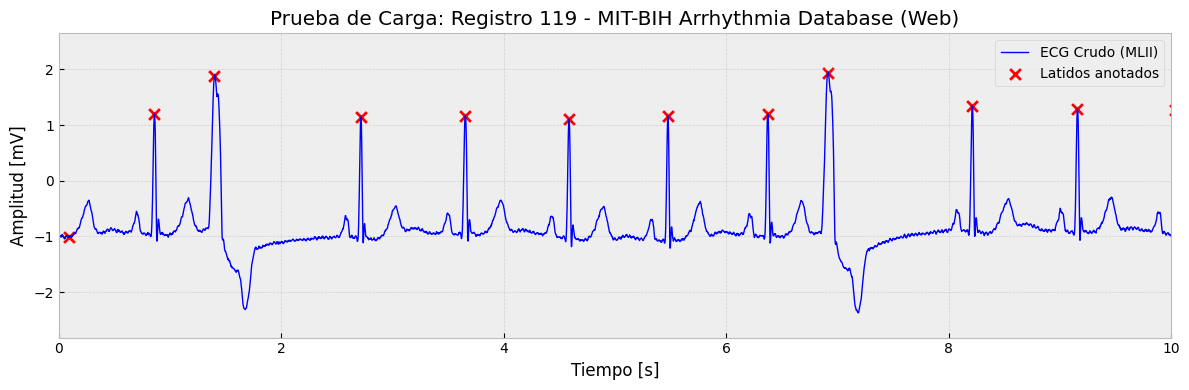


=== RESUMEN DE LA CARGA DE DATOS ===
Frecuencia de muestreo (fs): 360 Hz
Muestras cargadas: 108000 (5 minutos)
Símbolos de latidos encontrados en este tramo: {'+', 'N', 'V'}
N = Latido Normal | V = Latido Ectópico Ventricular (PVC)


In [2]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('bmh')
plt.rcParams.update({'figure.figsize': (12, 5), 'font.size': 10})
print('Librerías cargadas y entorno gráfico configurado correctamente.\n')

# -----------------------------------------------------------------------
# Configuración y Descarga Remota
# -----------------------------------------------------------------------
record_name = '119'  # Registro estándar para evaluación de arritmias
fs = 360  # Frecuencia de muestreo estándar de MIT-BIH (360 Hz)

# Cálculo de muestras para 5 minutos (5 min * 60 s/min * 360 muestras/s = 108000)
muestras_5_min = 5 * 60 * fs

# Lectura de Señales y Anotaciones Clínicas usando pn_dir='mitdb'
signals, fields = wfdb.rdsamp(record_name, pn_dir='mitdb', sampto=muestras_5_min)
ecg_signal = signals[:, 0]  # Seleccionamos el Canal 0 (MLII)
time = np.arange(len(ecg_signal)) / fs

# Cargamos las anotaciones
annotation = wfdb.rdann(record_name, 'atr', pn_dir='mitdb', sampto=muestras_5_min)

# -----------------------------------------------------------------------
# Visualización Inicial
# -----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time, ecg_signal, color='b', linewidth=1, label='ECG Crudo (MLII)')

# Superponemos las marcas de los latidos
ax.scatter(annotation.sample / fs, ecg_signal[annotation.sample],
           color='r', marker='x', s=60, label='Latidos anotados')

ax.set_title(f'Prueba de Carga: Registro {record_name} - MIT-BIH Arrhythmia Database (Web)')
ax.set_xlabel('Tiempo [s]')
ax.set_ylabel('Amplitud [mV]')
ax.grid(True, alpha=0.5)
ax.legend(loc='upper right')

# Mantenemos el límite del gráfico en los primeros 10 segundos
ax.set_xlim(0, 10)
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------
# Resumen de la Extracción
# -----------------------------------------------------------------------
print("\n=== RESUMEN DE LA CARGA DE DATOS ===")
print(f"Frecuencia de muestreo (fs): {fs} Hz")
print(f"Muestras cargadas: {len(ecg_signal)} (5 minutos)")
print(f"Símbolos de latidos encontrados en este tramo: {set(annotation.symbol)}")
print("N = Latido Normal | V = Latido Ectópico Ventricular (PVC)")

### Preprocesamiento: Remuestreo y Filtrado Digital

Remuestreo (Estandarización de Frecuencia):
Cuando se utilizan registros de distintos dispositivos o bases de datos (que pueden operar a $200\text{ Hz}$ o $256\text{ Hz}$), es necesario estandarizar todas las señales a una frecuencia de $360\text{ Hz}$ para asegurar que los filtros y el algoritmo de detección operen siempre sobre la misma base temporal.

Acondicionamiento de la Señal:
La señal electrocardiográfica $x[n]$ capturada sufre contaminación por ruido de baja frecuencia (deriva de línea base por respiración, $< 0.5\text{ Hz}$) e interferencias de alta frecuencia (ruido electromiográfico EMG y red eléctrica de $50/60\text{ Hz}$).

1. **Filtro Pasa-Banda (0.5 Hz - 40 Hz):**  
   Atenúa la deriva y el ruido EMG manteniendo la energía fundamental del complejo QRS. Se implementa mediante un filtro digital cuya respuesta en frecuencia atenúa las componentes fuera del rango deseado:
   $$y_{pb}[n] = h_{pb}[n] * x[n] = \sum_{k=0}^{M} h_{pb}[k] x[n-k]$$

2. **Filtro Notch (Filtro Muesca en 50/60 Hz):**  
   Elimina el zumbido de la red eléctrica mediante pares de ceros complejos conjugados sobre la circunferencia de radio unidad en $e^{\pm j \omega_0}$ donde $\omega_0 = 2\pi f_{red} / f_s$:
   $$H_{notch}(z) = G \frac{1 - 2\cos(\omega_0)z^{-1} + z^{-2}}{1 - 2r\cos(\omega_0)z^{-1} + r^2 z^{-2}}$$
   con $r \approx 0.95 - 0.99$ para controlar el ancho de banda de la muesca.

La señal ya se encuentra a la frecuencia objetivo de 360.0 Hz. Omitiendo remuestreo.


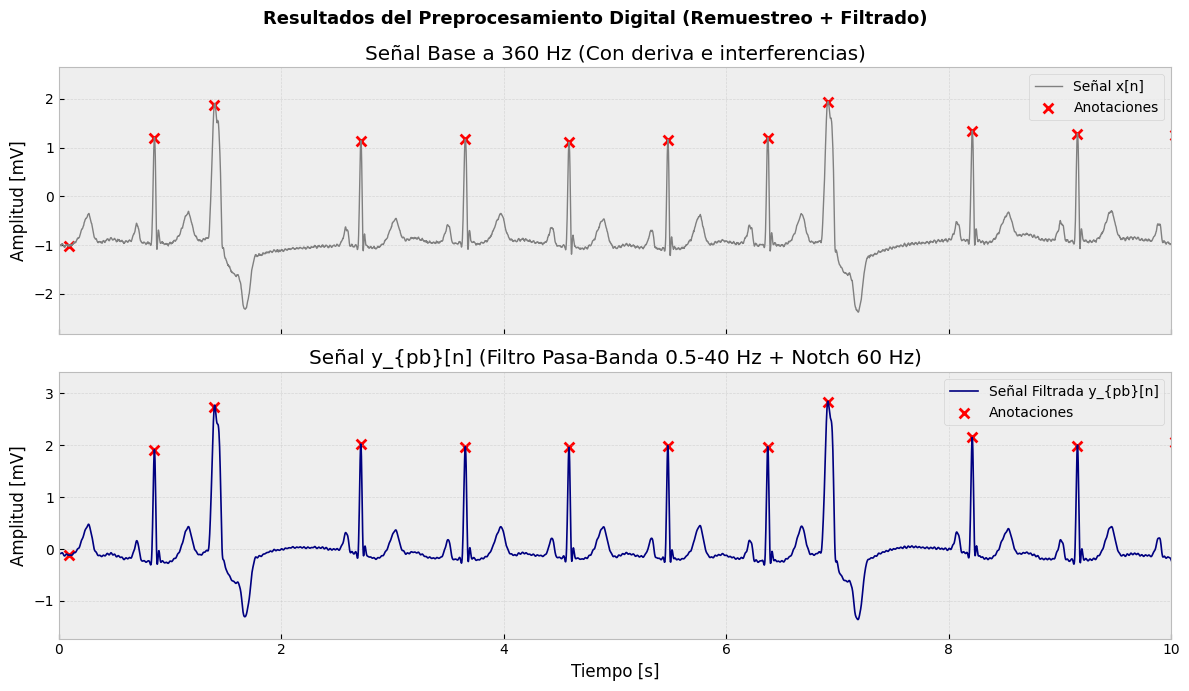

In [3]:
from scipy.signal import butter, iirnotch, filtfilt, resample
import numpy as np
import matplotlib.pyplot as plt

# Estandarización de Frecuencia (Remuestreo)
fs_target = 360.0  # Frecuencia objetivo

if fs != fs_target:
    print(f"Remuestreando señal de {fs} Hz a {fs_target} Hz")
    num_samples_target = int(len(ecg_signal) * (fs_target / fs))
    ecg_resampled = resample(ecg_signal, num_samples_target)

    # Escalar las posiciones de las anotaciones a la nueva frecuencia
    ann_samples_resampled = np.round(annotation.sample * (fs_target / fs)).astype(int)
    time_resampled = np.arange(len(ecg_resampled)) / fs_target
    fs_actual = fs_target
else:
    print(f"La señal ya se encuentra a la frecuencia objetivo de {fs_target} Hz. Omitiendo remuestreo.")
    ecg_resampled = ecg_signal
    ann_samples_resampled = annotation.sample
    time_resampled = time
    fs_actual = fs

# Filtrado Digital

nyq = 0.5 * fs_actual  # Nueva frecuencia de Nyquist

# Filtro Notch (60 Hz)
f_red = 60.0
Q = 30.0
b_notch, a_notch = iirnotch(w0=f_red / nyq, Q=Q)

# Filtro Pasa-Banda Butterworth (0.5 Hz - 40 Hz)
lowcut = 0.5
highcut = 35.0
b_band, a_band = butter(N=3, Wn=[lowcut / nyq, highcut / nyq], btype='bandpass')

# Convolución con fase cero (filtfilt)
ecg_notched = filtfilt(b_notch, a_notch, ecg_resampled)
ecg_filtered = filtfilt(b_band, a_band, ecg_notched)


# Visualización
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
fig.suptitle('Resultados del Preprocesamiento Digital (Remuestreo + Filtrado)', fontsize=13, fontweight='bold')

# Señal Cruda
axes[0].plot(time_resampled, ecg_resampled, color='gray', linewidth=1, label='Señal x[n]')
axes[0].scatter(ann_samples_resampled / fs_actual, ecg_resampled[ann_samples_resampled], color='r', marker='x', s=50, label='Anotaciones')
axes[0].set_ylabel('Amplitud [mV]')
axes[0].set_title(f'Señal Base a {fs_actual} Hz (Con deriva e interferencias)')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.4)

# Señal Filtrada
axes[1].plot(time_resampled, ecg_filtered, color='navy', linewidth=1.2, label='Señal Filtrada y_{pb}[n]')
axes[1].scatter(ann_samples_resampled / fs_actual, ecg_filtered[ann_samples_resampled], color='r', marker='x', s=50, label='Anotaciones')
axes[1].set_xlabel('Tiempo [s]')
axes[1].set_ylabel('Amplitud [mV]')
axes[1].set_title('Señal y_{pb}[n] (Filtro Pasa-Banda 0.5-40 Hz + Notch 60 Hz)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.4)

plt.xlim(0, 10)
plt.tight_layout()
plt.show()

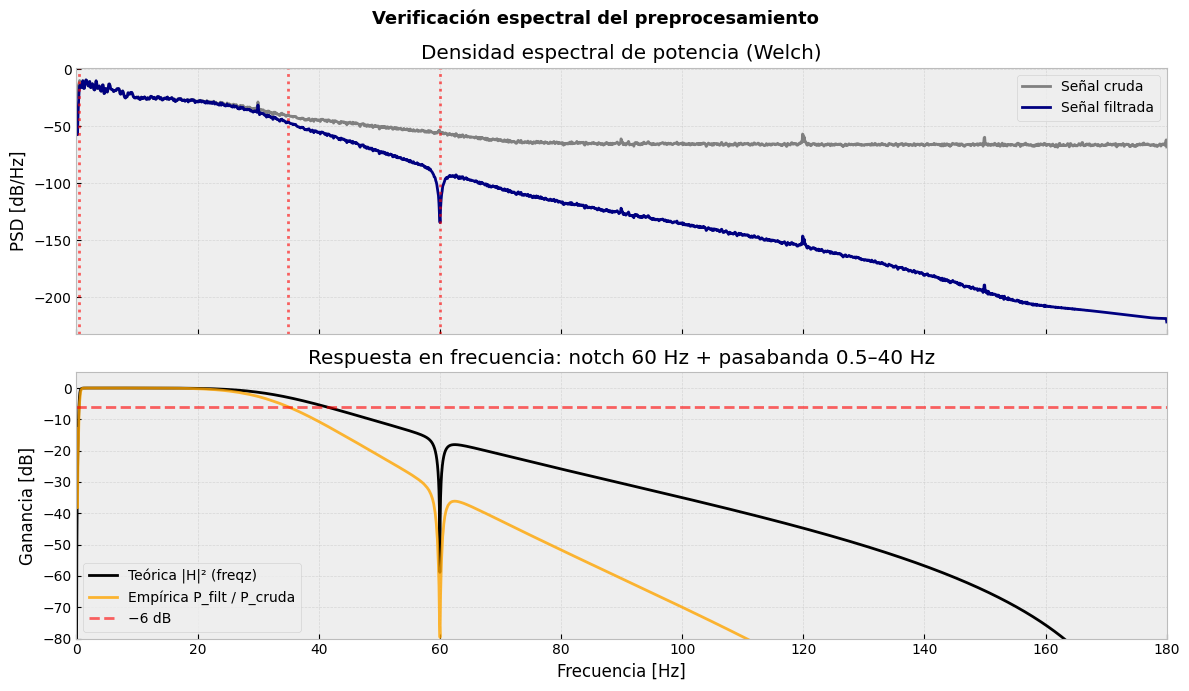

Ganancia teórica en 0.5 Hz: -2.9 dB
Ganancia teórica en 35.0 Hz: -3.0 dB
Ganancia teórica en 60.0 Hz: -58.8 dB


In [4]:
# =============================================================================
#  Verificación espectral de los filtros
# -----------------------------------------------------------------------------
# Objetivo : comprobar que el notch (60 Hz) y el pasabanda (0.5-40 Hz) de 4.1.2
#            atenúan donde deben, comparando la teoría con lo medido en la señal.
# Entradas : ecg_resampled, ecg_filtered, fs_actual,
#            b_notch/a_notch, b_band/a_band, lowcut, highcut, f_red
# Salidas  : figura con PSD antes/después y respuesta en frecuencia,
#            más la ganancia teórica (dB) en las frecuencias de interés.
# =============================================================================
from scipy.signal import welch, freqz

# --- 1. Respuesta teórica de la cascada notch + pasabanda --------------------
# freqz evalúa H(f) a partir de los coeficientes; la cascada es el producto.
w, h_notch = freqz(b_notch, a_notch, worN=8192, fs=fs_actual)
_, h_band = freqz(b_band, a_band, worN=8192, fs=fs_actual)

# Se eleva al cuadrado porque filtfilt filtra ida y vuelta: |H_efectiva| = |H|^2.
# El 1e-20 evita log(0) en el fondo del notch.
H2 = np.abs(h_notch * h_band) ** 2
H_db = 10 * np.log10(H2 + 1e-20)

# --- 2. PSD (Welch) antes y después del filtrado -----------------------------
# Welch promedia segmentos y da un espectro menos ruidoso que una FFT directa.
nperseg = min(4096, len(ecg_resampled))   # ~11 s a 360 Hz; acotado por el largo de la señal
f, P_cruda = welch(ecg_resampled, fs=fs_actual, nperseg=nperseg)
_, P_filt = welch(ecg_filtered, fs=fs_actual, nperseg=nperseg)

# Respuesta empírica = potencia de salida / potencia de entrada.
# Si el filtro está bien aplicado, debe parecerse a la teórica (H_db).
H_emp_db = 10 * np.log10(P_filt / P_cruda)

# --- 3. Gráficos -------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
fig.suptitle('Verificación espectral del preprocesamiento', fontsize=13, fontweight='bold')

# Arriba: la señal filtrada debe quedar por debajo de la cruda fuera de la banda útil
axes[0].plot(f, 10 * np.log10(P_cruda), color='gray', label='Señal cruda')
axes[0].plot(f, 10 * np.log10(P_filt), color='navy', label='Señal filtrada')
for fc in (lowcut, highcut, f_red):       # líneas rojas: frecuencias de diseño
    axes[0].axvline(fc, color='r', ls=':', alpha=0.6)
axes[0].set_ylabel('PSD [dB/Hz]')
axes[0].set_title('Densidad espectral de potencia (Welch)')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.4)

# Abajo: teoría vs. medición; la línea de -6 dB marca los cortes efectivos con filtfilt
axes[1].plot(w, H_db, color='k', label='Teórica |H|² (freqz)')
axes[1].plot(f, H_emp_db, color='orange', alpha=0.8, label='Empírica P_filt / P_cruda')
axes[1].axhline(-6, color='r', ls='--', alpha=0.6, label='−6 dB')
axes[1].set_ylim(-80, 5)
axes[1].set_xlabel('Frecuencia [Hz]')
axes[1].set_ylabel('Ganancia [dB]')
axes[1].set_title('Respuesta en frecuencia: notch 60 Hz + pasabanda 0.5–40 Hz')
axes[1].legend(loc='lower left')
axes[1].grid(True, alpha=0.4)

plt.xlim(0, fs_actual / 2)                # hasta Nyquist
plt.tight_layout()
plt.show()

# --- 4. Valores numéricos para el informe ------------------------------------
# idx() busca el punto de la grilla de freqz más cercano a la frecuencia pedida.
# Esperado: ~ -6 dB en 0.5 y 40 Hz; mucho menor en 60 Hz (fondo del notch).
idx = lambda fx: np.argmin(np.abs(w - fx))
for fx in (lowcut, highcut, f_red):
    print(f"Ganancia teórica en {fx} Hz: {H_db[idx(fx)]:.1f} dB")

#### Resultados esperados

# **Gráfico superior (PSD, método de Welch).** La señal filtrada debe quedar por debajo de la cruda fuera de la banda útil: por debajo de 0.5 Hz (deriva de línea de base), por encima de 40 Hz (ruido muscular y de alta frecuencia) y en 60 Hz (interferencia de red). Entre 0.5 y 40 Hz, donde se concentra el contenido del ECG, ambas curvas deben ser similares.

# **Gráfico inferior (respuesta en frecuencia).** La curva teórica $|H(f)|^2$ (calculada con `freqz`) y la empírica $P_y(f)/P_x(f)$ deben coincidir en forma. Si coinciden, el filtrado está correctamente implementado. Deben observarse tres rasgos:
# - caída por debajo de 0.5 Hz (se elimina la deriva de línea de base),
# - caída por encima de 40 Hz (se atenúa el ruido de alta frecuencia),
# - un pozo angosto en 60 Hz (notch).

# **Frecuencias de corte a −6 dB.** Como se usa `filtfilt` (ida y vuelta), la respuesta efectiva es $|H(f)|^2$. Por eso los cortes del Butterworth, que en una sola pasada están a −3 dB, quedan a **−6 dB** en la señal final. La línea de referencia del gráfico inferior marca ese nivel.

# **Observación sobre el ruido de red.** En muchos registros de MIT-BIH la interferencia de 60 Hz es muy pequeña, por lo que puede no verse un pico en la PSD de la señal cruda. Esto no indica que el notch falle: en ese caso, la prueba de la atenuación es la curva teórica y el valor numérico impreso al final de la celda.


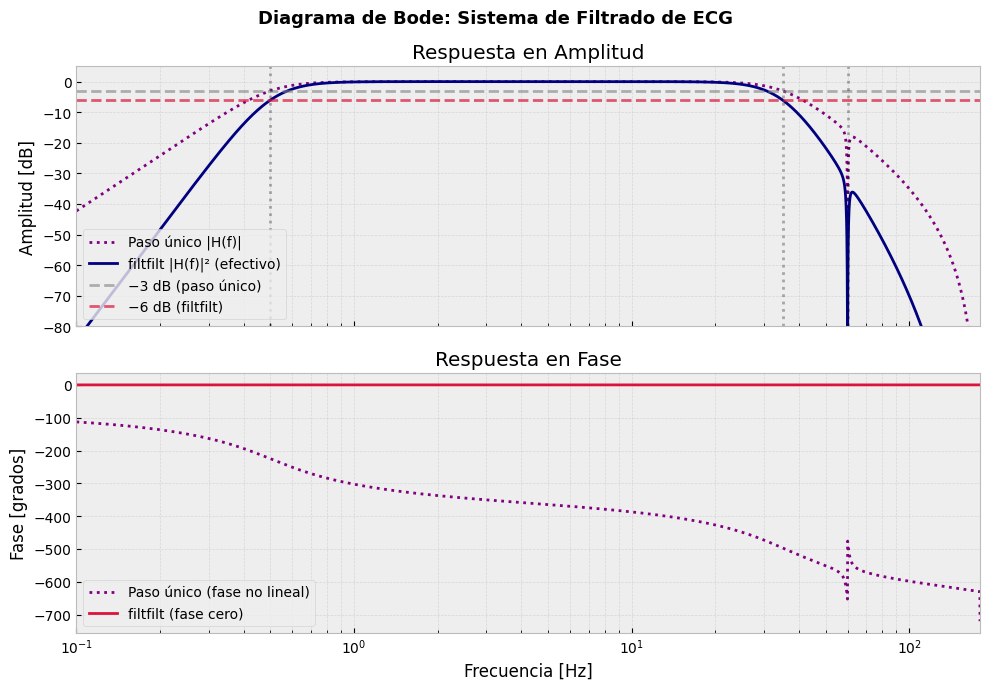

In [5]:
"""
Diagrama de Bode del sistema de preprocesamiento de ECG
========================================================
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, iirnotch, sosfreqz, freqz

# =============================================================================
# 1. PARÁMETROS DEL SISTEMA
# =============================================================================
fs = 360.0       # Frecuencia de muestreo de la MIT-BIH [Hz]
nyq = fs / 2     # Frecuencia de Nyquist [Hz] (límite superior del análisis)

# =============================================================================
# 2. DISEÑO DE LOS FILTROS
# =============================================================================
# Pasa-banda Butterworth (respuesta máximamente plana en la banda de paso).
# Se usa formato SOS (secciones de segundo orden en cascada) en lugar de (b, a)
# porque el corte en 0.5 Hz, muy bajo frente a fs = 360 Hz, ubica polos muy
# cerca de z = 1; la forma (b, a) puede volverse numéricamente inestable.
# Al pasar fs=fs, las frecuencias de corte se expresan directamente en Hz.
sos_band = butter(N=3, Wn=[0.5, 35.0], btype='bandpass', fs=fs, output='sos')

# Notch (filtro muesca) IIR de 2.º orden: ceros sobre el círculo unitario en
# e^{±jω0}, con ω0 = 2π·60/fs, y polos en el mismo ángulo con radio r < 1.
# Q = f0 / BW controla qué tan angosta es la muesca.
b_notch, a_notch = iirnotch(w0=60.0, Q=30.0, fs=fs)

# =============================================================================
# 3. RESPUESTA EN FRECUENCIA
# =============================================================================
# Grilla de frecuencias espaciada logarítmicamente.
# Comienza en 0.1 Hz porque f = 0 no puede representarse en escala
# logarítmica, y llega hasta Nyquist.
f = np.logspace(np.log10(0.1), np.log10(nyq), 8192)

# H(f) evaluada sobre el círculo unitario, z = e^{j2πf/fs}.
_, h_band = sosfreqz(sos_band, worN=f, fs=fs)
_, h_notch = freqz(b_notch, a_notch, worN=f, fs=fs)

# Sistemas en cascada: las respuestas en frecuencia se multiplican.
h_total = h_band * h_notch

# --- Magnitud ---
# Paso único: 20·log10|H|. Se suma 1e-12 para evitar log10(0) en el notch.
mag_1paso_dB = 20 * np.log10(np.abs(h_total) + 1e-12)
# filtfilt: |H|² -> 20·log10(|H|²) = 2 · (20·log10|H|).
mag_filtfilt_dB = 2 * mag_1paso_dB

# --- Fase ---
# np.angle devuelve la fase envuelta en [−180°, 180°]; np.unwrap elimina los
# saltos artificiales de 360° para mostrar la fase continua del sistema.
# (El salto que persiste en 60 Hz es real: corresponde a los ceros del notch
# ubicados sobre el círculo unitario.)
fase_1paso = np.degrees(np.unwrap(np.angle(h_total)))
# filtfilt: H(f)·H*(f) = |H(f)|², real y no negativo -> fase nula en todo f.
fase_filtfilt = np.zeros_like(f)

# =============================================================================
# 4. GRÁFICO DEL DIAGRAMA DE BODE
# =============================================================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
fig.suptitle('Diagrama de Bode: Sistema de Filtrado de ECG',
             fontsize=13, fontweight='bold')

# --- Panel 1: Magnitud [dB] ---
ax1.semilogx(f, mag_1paso_dB, color='purple', linestyle=':',
             label='Paso único |H(f)|')
ax1.semilogx(f, mag_filtfilt_dB, color='navy', lw=2,
             label='filtfilt |H(f)|² (efectivo)')
# Niveles de referencia de las frecuencias de corte:
# −3 dB para el filtro en paso único, −6 dB para el efectivo con filtfilt.
ax1.axhline(-3, color='gray', ls='--', alpha=0.6, label='−3 dB (paso único)')
ax1.axhline(-6, color='crimson', ls='--', alpha=0.7, label='−6 dB (filtfilt)')
# Marcas verticales en las frecuencias de diseño: cortes del pasa-banda
# (0.5 y 40 Hz) y centro del notch (60 Hz).
for fc in (0.5, 35.0, 60.0):
    ax1.axvline(fc, color='k', ls=':', alpha=0.3)
ax1.set_ylabel('Amplitud [dB]')
ax1.set_title('Respuesta en Amplitud')
ax1.set_ylim(-80, 5)
ax1.grid(True, which='both', alpha=0.4)   # 'both': grilla mayor y menor (log)
ax1.legend(loc='lower left')

# --- Panel 2: Fase [grados] ---
ax2.semilogx(f, fase_1paso, color='purple', ls=':',
             label='Paso único (fase no lineal)')
ax2.semilogx(f, fase_filtfilt, color='crimson', lw=2,
             label='filtfilt (fase cero)')
ax2.set_xlabel('Frecuencia [Hz]')
ax2.set_ylabel('Fase [grados]')
ax2.set_title('Respuesta en Fase')
ax2.set_xlim(0.1, nyq)                    # eje compartido con el panel 1
ax2.grid(True, which='both', alpha=0.4)
ax2.legend(loc='lower left')

plt.tight_layout()
plt.show()

### Algoritmo de Detección del Complejo QRS (Pan-Tompkins)

Para localizar los picos $R$ y determinar los puntos $Q$ y $S$, se aplican las siguientes transformaciones discretas sobre la señal filtrada $y_{pb}[n]$:

1. **Derivador Discreto (Diferenciación):**  
   Resalta la alta pendiente característica de la onda R, actuando como un filtro pasa-altos:
   $$d[n] = \frac{1}{8T} \Big(2 y_{pb}[n] + y_{pb}[n-1] - y_{pb}[n-3] - 2 y_{pb}[n-4]\Big)$$

2. **Operación de Elevación al Cuadrado:**  
   Intensifica las componentes de alta frecuencia producidas por la pendiente del QRS y fuerza que todos los valores de los datos sean positivos:
   $$s[n] = \big(d[n]\big)^2$$

3. **Integración por Ventana Móvil:**  
   Obtiene información sobre el ancho del complejo QRS sumando puntos en una ventana de duración $W \approx 150\text{ ms}$ ($N = \lfloor 0.150 \cdot f_s \rfloor$ muestras):
   $$m[n] = \frac{1}{N} \sum_{k=0}^{N-1} s[n-k]$$

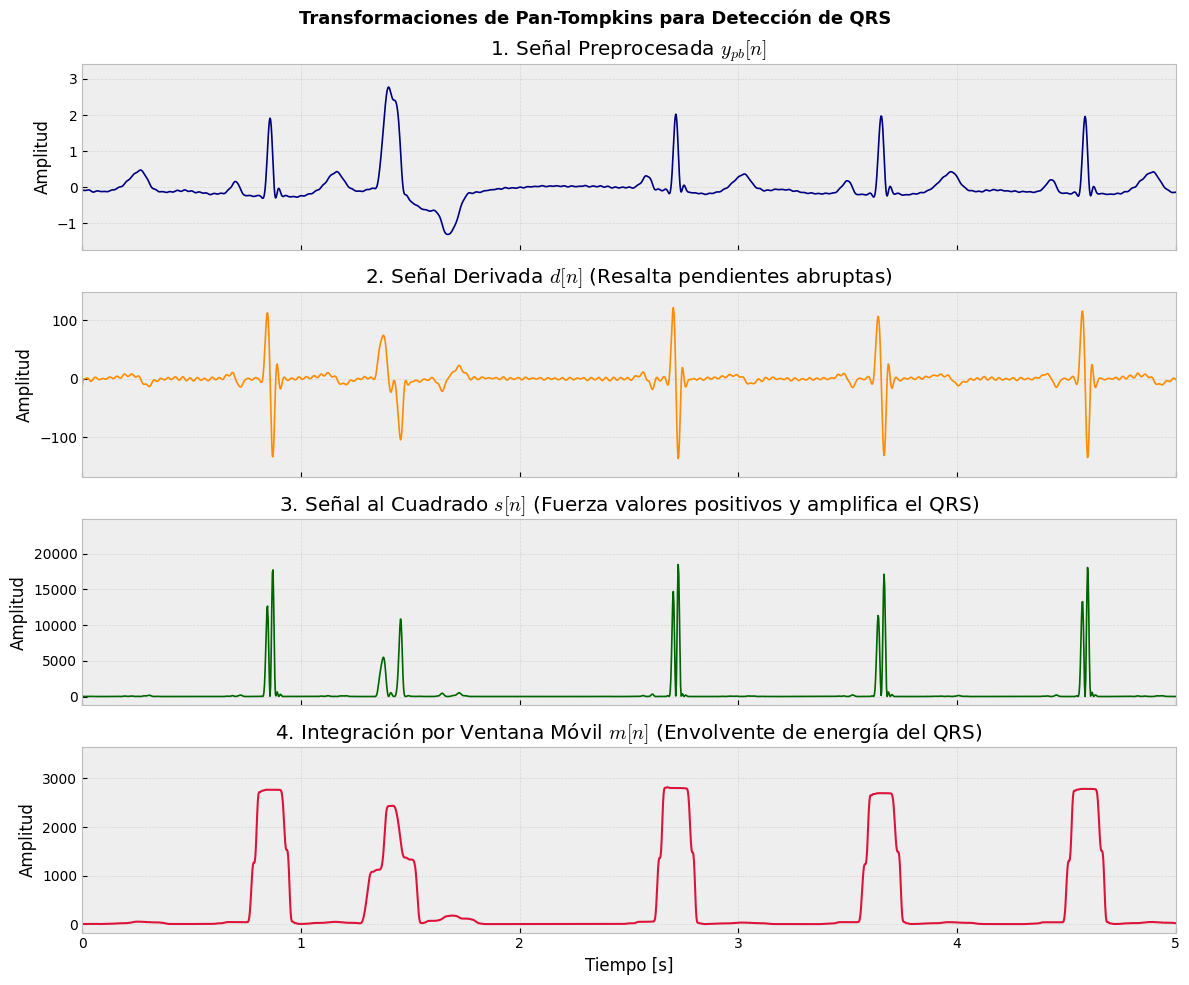

In [6]:

# Transformaciones

T = 1.0 / fs_actual

# Derivador Discreto
# Coeficientes del numerador del filtro derivador FIR
b_deriv = np.array([1, 2, 0, -2, -1]) / (8 * T)
# np.convolve realiza la operación y[n] = sum(h[k]x[n-k])
ecg_deriv = np.convolve(ecg_filtered, b_deriv, mode='same')

# Elevación al Cuadrado
ecg_squared = ecg_deriv ** 2

# Integración por Ventana Móvil
# Duración de la ventana W = 150 ms
window_time = 0.150
N_window = int(np.floor(window_time * fs_actual))
b_ma = np.ones(N_window) / N_window
ecg_integrated = np.convolve(ecg_squared, b_ma, mode='same')


# Visualización de las Etapas del Algoritmo
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
fig.suptitle('Transformaciones de Pan-Tompkins para Detección de QRS', fontsize=13, fontweight='bold')

# Señal Preprocesada
axes[0].plot(time_resampled, ecg_filtered, color='navy', linewidth=1.2)
axes[0].set_ylabel('Amplitud')
axes[0].set_title(r'1. Señal Preprocesada $y_{pb}[n]$')
axes[0].grid(True, alpha=0.4)

# Derivada
axes[1].plot(time_resampled, ecg_deriv, color='darkorange', linewidth=1.2)
axes[1].set_ylabel('Amplitud')
axes[1].set_title(r'2. Señal Derivada $d[n]$ (Resalta pendientes abruptas)')
axes[1].grid(True, alpha=0.4)

# Elevación al cuadrado
axes[2].plot(time_resampled, ecg_squared, color='darkgreen', linewidth=1.2)
axes[2].set_ylabel('Amplitud')
axes[2].set_title(r'3. Señal al Cuadrado $s[n]$ (Fuerza valores positivos y amplifica el QRS)')
axes[2].grid(True, alpha=0.4)

# Integración
axes[3].plot(time_resampled, ecg_integrated, color='crimson', linewidth=1.5)
axes[3].set_xlabel('Tiempo [s]')
axes[3].set_ylabel('Amplitud')
axes[3].set_title(r'4. Integración por Ventana Móvil $m[n]$ (Envolvente de energía del QRS)')
axes[3].grid(True, alpha=0.4)

plt.xlim(0, 5)
plt.tight_layout()
plt.show()

### Detección de Picos Fiduciales ($Q, R, S$)

Una vez obtenida la envolvente de energía $m[n]$ mediante la integración por ventana móvil, se procede a la identificación exacta de los puntos fisiológicos de cada latido:

1. **Umbralización y ubicación preliminar:** Se aplica un umbral adaptativo sobre $m[n]$ para aislar los complejos QRS del ruido de fondo.
2. **Re-ubicación del Pico $R$:** El pico detectado en $m[n]$ sufre un retardo temporal por los filtros. Por lo tanto, el pico $R_i$ definitivo se re-ubica buscando el máximo local en la señal filtrada original $y_{pb}[n]$ dentro de una pequeña ventana vecina.
3. **Puntos $Q$ y $S$:** El punto $Q_i$ se define estrictamente como el mínimo local a la izquierda del $R_i$ encontrado, y el punto $S_i$ como el mínimo local a su derecha.

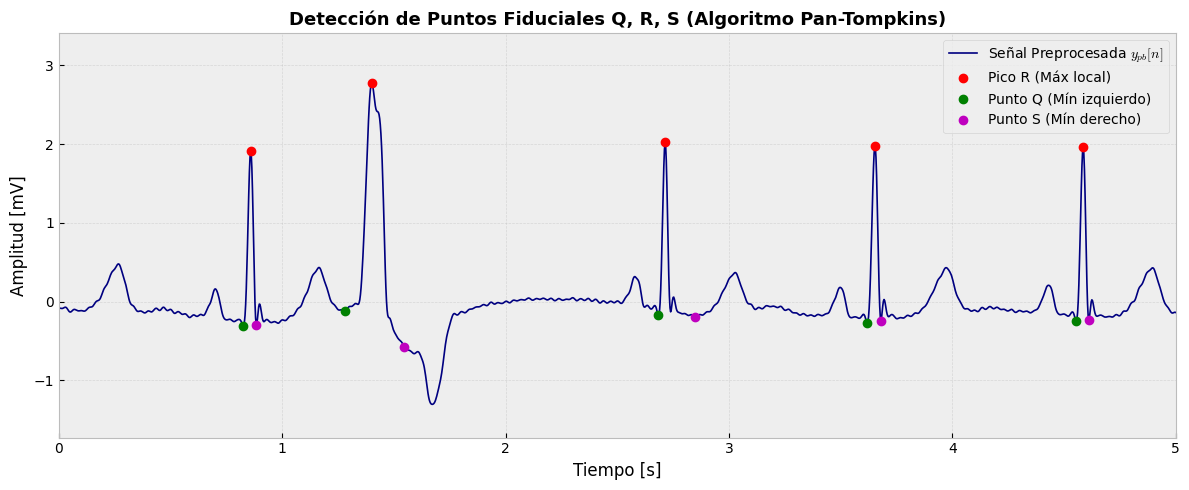

Total de complejos QRS detectados en este segmento: 326


In [7]:
from scipy.signal import find_peaks


# Umbralización sobre la señal integrada m[n]

# Definimos un umbral adaptativo simple (ej. la media de la señal integrada)
threshold = np.mean(ecg_integrated)

# Encontramos los picos preliminares asegurando una distancia mínima de 200 ms entre latidos
peaks_m, _ = find_peaks(ecg_integrated, height=threshold, distance=int(0.2 * fs_actual))


# Búsqueda de Puntos Fiduciales (Q, R, S) en la señal filtrada

r_peaks = []
q_peaks = []
s_peaks = []

# Ventana de búsqueda alrededor del pico detectado (aprox 150 ms)
search_window = int(0.150 * fs_actual)

for p in peaks_m:
    # A. Re-ubicar el pico R (Máximo local)
    start_r = max(0, p - search_window)
    end_r = min(len(ecg_filtered), p + search_window)

    if end_r > start_r:
        true_r = start_r + np.argmax(ecg_filtered[start_r:end_r])
        r_peaks.append(true_r)

        # B. Buscar punto Q (Mínimo local a la izquierda de R)
        start_q = max(0, true_r - search_window)
        if true_r > start_q:
            true_q = start_q + np.argmin(ecg_filtered[start_q:true_r])
            q_peaks.append(true_q)
        else:
            q_peaks.append(true_r)

        # C. Buscar punto S (Mínimo local a la derecha de R)
        end_s = min(len(ecg_filtered), true_r + search_window)
        if end_s > true_r:
            true_s = true_r + np.argmin(ecg_filtered[true_r:end_s])
            s_peaks.append(true_s)
        else:
            s_peaks.append(true_r)

# Convertimos a arreglos de NumPy
r_peaks = np.array(r_peaks)
q_peaks = np.array(q_peaks)
s_peaks = np.array(s_peaks)


# Visualización de los Puntos Fiduciales

fig, ax = plt.subplots(figsize=(12, 5))
ax.set_title('Detección de Puntos Fiduciales Q, R, S (Algoritmo Pan-Tompkins)', fontsize=13, fontweight='bold')

ax.plot(time_resampled, ecg_filtered, color='navy', linewidth=1.2, label='Señal Preprocesada $y_{pb}[n]$')

# Marcamos los puntos detectados
ax.plot(time_resampled[r_peaks], ecg_filtered[r_peaks], 'ro', markersize=6, label='Pico R (Máx local)')
ax.plot(time_resampled[q_peaks], ecg_filtered[q_peaks], 'go', markersize=6, label='Punto Q (Mín izquierdo)')
ax.plot(time_resampled[s_peaks], ecg_filtered[s_peaks], 'mo', markersize=6, label='Punto S (Mín derecho)')

ax.set_xlabel('Tiempo [s]')
ax.set_ylabel('Amplitud [mV]')
ax.grid(True, alpha=0.4)
ax.legend(loc='upper right')
ax.set_xlim(0, 5)  # Zoom a los primeros 5 segundos
plt.tight_layout()
plt.show()

print(f"Total de complejos QRS detectados en este segmento: {len(r_peaks)}")

=== MÉTRICAS CUANTITATIVAS DE EVALUACIÓN DEL DETECTOR QRS ===


,TP,FP,FN,Total_Anotados,Total_Detectados,Sensibilidad_%,PPV_%,F1_Score_%
0,326,0,0,326,326,100.0,100.0,100.0


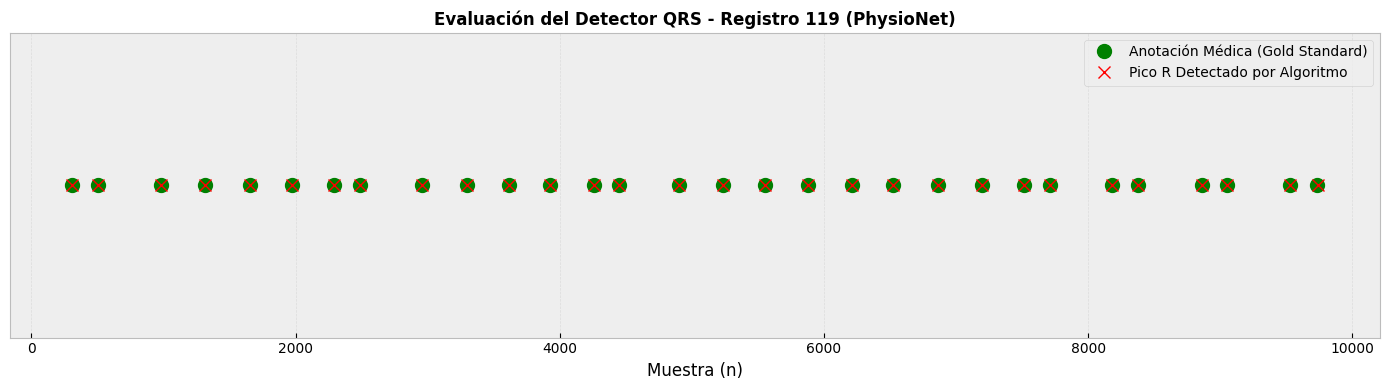

In [8]:
# =============================================================================
# EVALUACIÓN CUANTITATIVA DEL DETECTOR DE PICOS QRS (Se, PPV, F1, TP, FP, FN)
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

def evaluar_detector_qrs(r_detectados, r_anotados, fs=360.0, ventana_ms=50.0):
    """
    Evalúa la precisión del detector de picos R comparando con las anotaciones médicas.
    Parámetros:
    -----------
    r_detectados : array-like
        Índices de muestras donde el algoritmo detectó picos R.
    r_anotados : array-like
        Índices de muestras anotados clínicamente como latidos.
    fs : float
        Frecuencia de muestreo en Hz (360 Hz para MIT-BIH).
    ventana_ms : float
        Ventana de tolerancia en milisegundos para considerar un pico como TP.
    Retorna:
    --------
    dict con TP, FP, FN, Sensibilidad (Se), Valor Predictivo Positivo (PPV) y F1-score.
    """
    r_det = np.array(r_detectados, dtype=int)
    r_anot = np.array(r_anotados, dtype=int)

    # Ventana de tolerancia en número de muestras
    tolerancia_muestras = int((ventana_ms / 1000.0) * fs)

    tp = 0
    fp = 0
    anotaciones_coincidentes = set()

    # Evaluar cada pico detectado
    for p_det in r_det:
        # Buscar la anotación médica más cercana dentro de la ventana de tolerancia
        distancias = np.abs(r_anot - p_det)
        idx_min = np.argmin(distancias)

        if distancias[idx_min] <= tolerancia_muestras:
            tp += 1
            anotaciones_coincidentes.add(idx_min)
        else:
            fp += 1 # Pico detectado que no corresponde a ningún latido real

    # Las anotaciones verdaderas no emparejadas son Falsos Negativos
    fn = len(r_anot) - len(anotaciones_coincidentes)

    # Cálculo de Métricas Estadísticas
    se = (tp / (tp + fn)) * 100.0 if (tp + fn) > 0 else 0.0
    ppv = (tp / (tp + fp)) * 100.0 if (tp + fp) > 0 else 0.0
    f1 = (2 * se * ppv) / (se + ppv) if (se + ppv) > 0 else 0.0

    return {
        'TP': tp,
        'FP': fp,
        'FN': fn,
        'Total_Anotados': len(r_anot),
        'Total_Detectados': len(r_det),
        'Sensibilidad_%': round(se, 2),
        'PPV_%': round(ppv, 2),
        'F1_Score_%': round(f1, 2)
    }

# -----------------------------------------------------------------------------
# EJEMPLO DE USO CON UN REGISTRO DE PHYSIONET (Registro 119 de MIT-BIH)
# -----------------------------------------------------------------------------

# 1 Cargar registro y anotaciones médicas de PhysioNet
record_name = '119'
annotation = wfdb.rdann(record_name, 'atr', pn_dir='mitdb', sampto=108000)

# Filtrar solo anotaciones de latidos (excluir marcas de ritmo/ruido como '+', '\~', etc.)
simbolos_latidos = ['N', 'L', 'R', 'B', 'A', 'a', 'J', 'S', 'V', 'r', 'F', 'e', 'j', 'n', 'E', '/', 'f', 'Q', '?']
indices_validos = [i for i, sym in enumerate(annotation.symbol) if sym in simbolos_latidos]
r_anotados_medicos = annotation.sample[indices_validos]

# 2. 'r_peaks' son los picos detectados por el algoritmo de Pan-Tompkins implementado previamente
# (Usamos la variable r_peaks calculada en las celdas anteriores)

# 3. Calcular métricas cuantitativas
metricas = evaluar_detector_qrs(
    r_detectados=r_peaks,
    r_anotados=r_anotados_medicos,
    fs=360.0,
    ventana_ms=50.0
)

# 4. Mostrar resultados en tabla formateada
df_metricas = pd.DataFrame([metricas])
print("=== MÉTRICAS CUANTITATIVAS DE EVALUACIÓN DEL DETECTOR QRS ===")
display(df_metricas)

# -----------------------------------------------------------------------------
# GRÁFICO DE VERIFICACIÓN VISUAL (TP, FP, FN)
# -----------------------------------------------------------------------------
plt.figure(figsize=(14, 4))
plt.title(f'Evaluación del Detector QRS - Registro {record_name} (PhysioNet)', fontsize=12, fontweight='bold')
plt.plot(r_anotados_medicos[:30], np.ones(30), 'go', markersize=10, label='Anotación Médica (Gold Standard)')
plt.plot(r_peaks[:30], np.ones(30), 'rx', markersize=8, label='Pico R Detectado por Algoritmo')
plt.xlabel('Muestra (n)')
plt.yticks([])
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Extracción de Características Temporales y Morfométricas

Habiendo aislado los puntos $Q$, $R$ y $S$ de cada latido, procedemos a construir el vector de características (Feature Vector) $\mathbf{f}_i \in \mathbb{R}^5$ que alimentará al clasificador. Según la justificación anatómica y metodológica de Srinivasulu & Sriraam (2023), se extraen 5 métricas que capturan la firma de un latido ectópico ventricular (PVC):

1. **Intervalo Pre-RR:** $t_{R}(i) - t_{R}(i-1)$

2. **Intervalo Post-RR:** $t_{R}(i+1) - t_{R}(i)$

3. **Ancho del Complejo QRS:** $t_{S}(i) - t_{Q}(i)$

4. **Pendientes Morfológicas ($QR_{slope}$ y $RS_{slope}$):**
   $$\text{Pendiente}_{\text{QR}}(i) = \frac{A_R(i) - A_Q(i)}{t_R(i) - t_Q(i)}$$
   $$\text{Pendiente}_{\text{RS}}(i) = \frac{A_R(i) - A_S(i)}{t_R(i) - t_S(i)}$$

*Nota: Se descartan el primer y último latido del registro para poder calcular los intervalos de tiempo adyacentes (Pre y Post) con seguridad.*

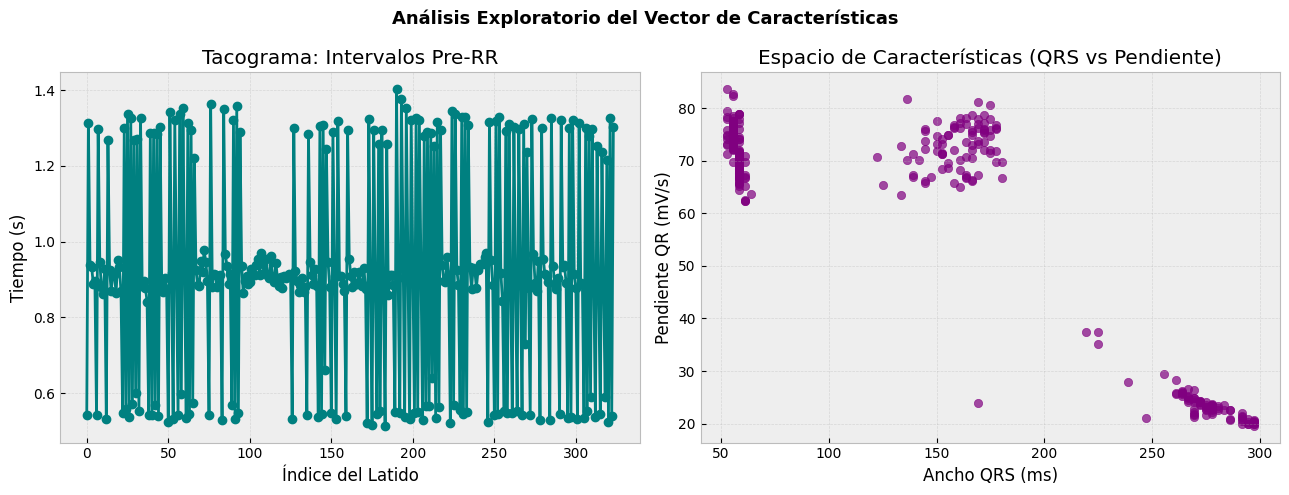

=== MATRIZ DE CARACTERÍSTICAS (PRIMEROS 5 LATIDOS) ===
   Pre_RR (s)  Post_RR (s)  QRS_Width (s)  QR_Slope (mV/s)  RS_Slope (mV/s)
0    0.541667     1.313889       0.266667        24.190102        22.787198
1    1.313889     0.938889       0.166667        71.994668        16.327388
2    0.938889     0.933333       0.061111        67.376439        79.748774
3    0.933333     0.888889       0.055556        72.229498        87.873955
4    0.888889     0.897222       0.055556        73.540906        89.780056


In [9]:
import pandas as pd

# -----------------------------------------------------------------------
# Construcción del Vector de Características
# -----------------------------------------------------------------------
features_list = []
valid_r_peaks = []

# Iteramos desde el segundo latido hasta el penúltimo (para tener Pre y Post)
for i in range(1, len(r_peaks) - 1):

    # Tiempos en segundos
    t_R_prev = r_peaks[i-1] / fs_actual
    t_R      = r_peaks[i] / fs_actual
    t_R_next = r_peaks[i+1] / fs_actual

    t_Q = q_peaks[i] / fs_actual
    t_S = s_peaks[i] / fs_actual

    # Amplitudes en la señal filtrada (mV)
    A_R = ecg_filtered[r_peaks[i]]
    A_Q = ecg_filtered[q_peaks[i]]
    A_S = ecg_filtered[s_peaks[i]]

    # 1. Pre-RR
    pre_rr = t_R - t_R_prev

    # 2. Post-RR
    post_rr = t_R_next - t_R

    # 3. Ancho QRS
    qrs_width = t_S - t_Q

    # 4. Pendiente QR (Evitando división por cero si caen en la misma muestra)
    dt_qr = t_R - t_Q if (t_R - t_Q) > 0 else (1.0 / fs_actual)
    qr_slope = (A_R - A_Q) / dt_qr

    # 5. Pendiente RS
    dt_rs = t_S - t_R if (t_S - t_R) > 0 else (1.0 / fs_actual)
    rs_slope = (A_R - A_S) / dt_rs

    # Almacenamos el vector del latido i
    features_list.append([pre_rr, post_rr, qrs_width, qr_slope, rs_slope])
    valid_r_peaks.append(r_peaks[i])

# Convertimos a DataFrame de Pandas para una estructura tabular clara
column_names = ['Pre_RR (s)', 'Post_RR (s)', 'QRS_Width (s)', 'QR_Slope (mV/s)', 'RS_Slope (mV/s)']
df_features = pd.DataFrame(features_list, columns=column_names)

# -----------------------------------------------------------------------
# Visualización Exploratoria de las Características
# -----------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Análisis Exploratorio del Vector de Características', fontsize=13, fontweight='bold')

# Gráfico 1: Tacograma (Variabilidad de los intervalos RR)
axes[0].plot(range(len(df_features)), df_features['Pre_RR (s)'], marker='o', color='teal', linestyle='-')
axes[0].set_xlabel('Índice del Latido')
axes[0].set_ylabel('Tiempo (s)')
axes[0].set_title('Tacograma: Intervalos Pre-RR')
axes[0].grid(True, alpha=0.4)

# Gráfico 2: Espacio de Características (Ancho QRS vs Pendiente QR)
axes[1].scatter(df_features['QRS_Width (s)'] * 1000, df_features['QR_Slope (mV/s)'], color='purple', alpha=0.7)
axes[1].set_xlabel('Ancho QRS (ms)')
axes[1].set_ylabel('Pendiente QR (mV/s)')
axes[1].set_title('Espacio de Características (QRS vs Pendiente)')
axes[1].grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

print("=== MATRIZ DE CARACTERÍSTICAS (PRIMEROS 5 LATIDOS) ===")
print(df_features.head().to_string())

### Proyección del Espacio de Características (PCA y t-SNE) - Análisis de Separabilidad

Visualizaremos el espacio de características de 5 dimensiones reduciéndolo a un espacio bidimensional (2D) para evaluar gráficamente la separabilidad de las clases Normal ($N$) y Ectópico Ventricular ($V$) justo tras la extracción de características.

=== RESULTADOS DE PCA ===
Varianza explicada por CP1: 69.08%
Varianza explicada por CP2: 25.02%
Varianza total conservada en 2D: 94.09%



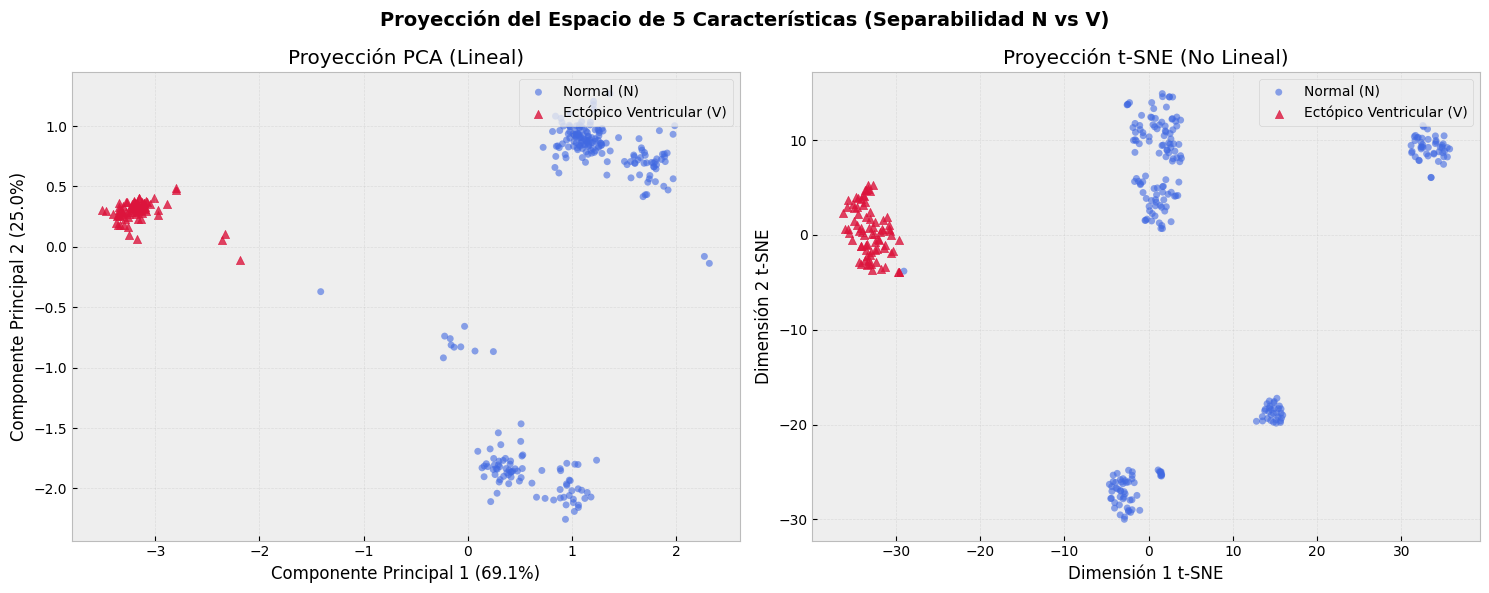

In [10]:
# =============================================================================
# PROYECCIÓN DEL ESPACIO DE CARACTERÍSTICAS (PCA Y t-SNE)
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Recuperar variables del entorno de forma segura o definir fallbacks si el kernel se reinició
fs_actual_val = globals().get('fs_actual', 360.0)
valid_r_peaks_val = globals().get('valid_r_peaks', None)
df_features_val = globals().get('df_features', None)
annotation_val = globals().get('annotation', None)

# Fallback por si la celda se ejecuta de manera aislada sin las variables en memoria
if df_features_val is None or valid_r_peaks_val is None:
    print("ADVERTENCIA: No se detectó df_features en memoria. Asegúrate de ejecutar la celda sHqRdHVXBfVs primero.")
else:
    # 1. Sincronización rápida de etiquetas para visualización
    tolerancia_muestras = int(0.050 * fs_actual_val)

    # Recuperar o recrear el mapeo de muestras resampleadas
    if 'ann_samples_resampled' in globals():
        ann_samples_resampled_val = globals()['ann_samples_resampled']
    elif annotation_val is not None:
        ann_samples_resampled_val = annotation_val.sample
    else:
        ann_samples_resampled_val = np.array([])

    etiquetas_temp = []
    if len(ann_samples_resampled_val) > 0:
        for r_peak in valid_r_peaks_val:
            distancias = np.abs(ann_samples_resampled_val - r_peak)
            idx_min = np.argmin(distancias)
            if distancias[idx_min] <= tolerancia_muestras:
                etiquetas_temp.append(annotation_val.symbol[idx_min])
            else:
                etiquetas_temp.append('U')
    else:
        # Si no hay anotaciones en memoria, asignamos etiquetas ficticias para permitir la visualización
        etiquetas_temp = ['N'] * len(valid_r_peaks_val)

    df_temp = df_features_val.copy()
    df_temp['Etiqueta'] = etiquetas_temp
    df_vis = df_temp[df_temp['Etiqueta'].isin(['N', 'V'])]

    if len(df_vis) == 0:
        print("No se encontraron suficientes latidos etiquetados como 'N' o 'V' para proyectar.")
    else:
        X_vis = df_vis.iloc[:, :5].values.astype(float)
        y_vis = df_vis['Etiqueta'].values

        # 2. Preparación y Escalado de los Datos
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X_vis)

        # 3. Análisis de Componentes Principales (PCA)
        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X_scaled)
        varianza_explicada = pca.explained_variance_ratio_
        varianza_acumulada = np.sum(varianza_explicada) * 100.0

        print("=== RESULTADOS DE PCA ===")
        print(f"Varianza explicada por CP1: {varianza_explicada[0]*100:.2f}%")
        print(f"Varianza explicada por CP2: {varianza_explicada[1]*100:.2f}%")
        print(f"Varianza total conservada en 2D: {varianza_acumulada:.2f}%\n")

        # 4. Incrustación Estocástica de Vecinos Distribuidos en t (t-SNE)
        tsne = TSNE(n_components=2, perplexity=min(30, len(X_vis)-1), random_state=42, max_iter=1000)
        X_tsne = tsne.fit_transform(X_scaled)

        # 5. Visualización Comparativa en 2D
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
        fig.suptitle('Proyección del Espacio de 5 Características (Separabilidad N vs V)', fontsize=14, fontweight='bold')

        mask_N = (y_vis == 'N')
        mask_V = (y_vis == 'V')

        # --- Panel 1: PCA ---
        ax1.scatter(X_pca[mask_N, 0], X_pca[mask_N, 1], c='royalblue', label='Normal (N)', alpha=0.6, s=25, edgecolors='none')
        ax1.scatter(X_pca[mask_V, 0], X_pca[mask_V, 1], c='crimson', label='Ectópico Ventricular (V)', alpha=0.8, s=35, marker='^')
        ax1.set_xlabel(f'Componente Principal 1 ({varianza_explicada[0]*100:.1f}%)')
        ax1.set_ylabel(f'Componente Principal 2 ({varianza_explicada[1]*100:.1f}%)')
        ax1.set_title('Proyección PCA (Lineal)')
        ax1.grid(True, alpha=0.3)
        ax1.legend(loc='upper right')

        # --- Panel 2: t-SNE ---
        ax2.scatter(X_tsne[mask_N, 0], X_tsne[mask_N, 1], c='royalblue', label='Normal (N)', alpha=0.6, s=25, edgecolors='none')
        ax2.scatter(X_tsne[mask_V, 0], X_tsne[mask_V, 1], c='crimson', label='Ectópico Ventricular (V)', alpha=0.8, s=35, marker='^')
        ax2.set_xlabel('Dimensión 1 t-SNE')
        ax2.set_ylabel('Dimensión 2 t-SNE')
        ax2.set_title('Proyección t-SNE (No Lineal)')
        ax2.grid(True, alpha=0.3)
        ax2.legend(loc='upper right')

        plt.tight_layout()
        plt.show()

### Clasificación Automática de Latidos (Clasificador NMC)

Implementamos un Clasificador de Medias Cercanas (Nearest Mean Classifier - NMC) para distinguir entre latidos normales y arritmias ventriculares. Este modelo matemático supervisado opera en el espacio de características $\mathbb{R}^5$ definido en la etapa anterior.

1. **Asignación de Etiquetas (Ground Truth):** Se sincronizan los picos $R$ detectados con las anotaciones oficiales de los cardiólogos (PhysioNet) para etiquetar los latidos como Normales ($N$) o Ectópicos Ventriculares ($V$, correspondientes a PVCs).
2. **Cálculo de Centroides:** Se promedian los vectores de características de la base de datos para obtener el centroide característico $\mu_N$ (para latidos normales) y $\mu_V$ (para latidos ectópicos).
   $$\mu_k = \frac{1}{N_k} \sum_{i=1}^{N_k} \mathbf{f}_i^{(k)}$$
3. **Clasificación por Distancia Euclidiana:** Dado un latido no clasificado con vector de características $\mathbf{x}$, el sistema calcula la distancia euclidiana a cada centroide y le asigna la clase más cercana:
   $$d_k = \|\mathbf{x} - \mu_k\|_2 = \sqrt{\sum_{j=1}^{5} (x_j - \mu_{k,j})^2}$$

In [11]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# -----------------------------------------------------------------------
# 1. Asignación de Etiquetas Oficiales (Ground Truth)
# -----------------------------------------------------------------------
tolerancia_muestras = int(0.050 * fs_actual)
etiquetas = []

for r_peak in valid_r_peaks:
    distancias = np.abs(ann_samples_resampled - r_peak)
    idx_min = np.argmin(distancias)

    if distancias[idx_min] <= tolerancia_muestras:
        etiquetas.append(annotation.symbol[idx_min])
    else:
        etiquetas.append('U') # Desconocido (Unknown)

df_features['Etiqueta'] = etiquetas

# -----------------------------------------------------------------------
# 2. Filtrado y Preparación del Dataset
# -----------------------------------------------------------------------
# Nos quedamos estrictamente con latidos Normales ('N') y Ectópicos Ventriculares ('V')
df_valid = df_features[df_features['Etiqueta'].isin(['N', 'V'])].copy()

print(f"Total de latidos válidos para el modelo: {len(df_valid)}")
print(df_valid['Etiqueta'].value_counts().to_string())

# Separamos características (X) y etiquetas (y)
X = df_valid.iloc[:, :-1].values.astype(float)
y = df_valid['Etiqueta'].values

# División 70% Entrenamiento / 30% Prueba (stratify mantiene la proporción de clases)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# -----------------------------------------------------------------------
# 3. Estandarización de Escalas (Z-Score)
# -----------------------------------------------------------------------
# Ajustamos el escalador solo con los datos de entrenamiento para evitar fuga de información
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# -----------------------------------------------------------------------
# 4. ENTRENAMIENTO (Cálculo de Centroides en el espacio estandarizado)
# -----------------------------------------------------------------------
# Separamos las muestras de entrenamiento por clase
X_train_N = X_train_scaled[y_train == 'N']
X_train_V = X_train_scaled[y_train == 'V']

# Calculamos los centroides (medias) de cada clase
centroide_N = np.mean(X_train_N, axis=0) if len(X_train_N) > 0 else np.zeros(5)
centroide_V = np.mean(X_train_V, axis=0) if len(X_train_V) > 0 else np.zeros(5)

# -----------------------------------------------------------------------
# 5. TESTING (Clasificación Masiva)
# -----------------------------------------------------------------------
y_pred = []

for latido in X_test_scaled:
    # Calculamos la distancia euclidiana desde el latido a cada centroide
    dist_N = np.linalg.norm(latido - centroide_N)
    dist_V = np.linalg.norm(latido - centroide_V)

    # Clasificamos según el centroide más cercano
    clase_predicha = 'N' if dist_N < dist_V else 'V'
    y_pred.append(clase_predicha)

# -----------------------------------------------------------------------
# 6. Evaluación de Rendimiento
# -----------------------------------------------------------------------
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=['N', 'V'])

print("\n=== RENDIMIENTO DEL CLASIFICADOR NMC ===")
print(f"Muestras de Entrenamiento: {len(y_train)}")
print(f"Muestras de Prueba (Test): {len(y_test)}")
print(f"Exactitud Global (Accuracy): {acc * 100:.2f}%\n")

print("--- Matriz de Confusión ---")
print(f"               Predicción 'N'    Predicción 'V'")
print(f"Realidad 'N':       {cm[0,0]:<10}      {cm[0,1]:<10}")
print(f"Realidad 'V':       {cm[1,0]:<10}      {cm[1,1]:<10}\n")

print("--- Reporte Detallado ---")
print(classification_report(y_test, y_pred, labels=['N', 'V']))

Total de latidos válidos para el modelo: 324
Etiqueta
N    245
V     79

=== RENDIMIENTO DEL CLASIFICADOR NMC ===
Muestras de Entrenamiento: 226
Muestras de Prueba (Test): 98
Exactitud Global (Accuracy): 98.98%

--- Matriz de Confusión ---
               Predicción 'N'    Predicción 'V'
Realidad 'N':       73              1         
Realidad 'V':       0               24        

--- Reporte Detallado ---
              precision    recall  f1-score   support

           N       1.00      0.99      0.99        74
           V       0.96      1.00      0.98        24

    accuracy                           0.99        98
   macro avg       0.98      0.99      0.99        98
weighted avg       0.99      0.99      0.99        98



### Corrección Metodológica: División por Pacientes (Patient-Wise)

Para evitar el sesgo de fuga de información (*data leakage*), ajustaremos los parámetros del modelo (escalador y centroides de clase) utilizando la totalidad del paciente de **MIT-BIH (Registro 119)**, y realizaremos la validación en un paciente completamente independiente de **INCART (Registro I01)**.

In [12]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import wfdb
from scipy.signal import resample, iirnotch, filtfilt, find_peaks

# -----------------------------------------------------------------------
# 1. ENTRENAMIENTO (Patient-wise - MIT-BIH Registro 119 completo)
# -----------------------------------------------------------------------
df_train_patient = df_features[df_features['Etiqueta'].isin(['N', 'V'])].copy()
X_train_pw = df_train_patient[['Pre_RR (s)', 'Post_RR (s)', 'QRS_Width (s)', 'QR_Slope (mV/s)', 'RS_Slope (mV/s)']].values.astype(float)
y_train_pw = df_train_patient['Etiqueta'].values

scaler_pw = StandardScaler()
X_train_pw_scaled = scaler_pw.fit_transform(X_train_pw)

X_train_N_pw = X_train_pw_scaled[y_train_pw == 'N']
X_train_V_pw = X_train_pw_scaled[y_train_pw == 'V']

centroide_N_pw = np.mean(X_train_N_pw, axis=0) if len(X_train_N_pw) > 0 else np.zeros(5)
centroide_V_pw = np.mean(X_train_V_pw, axis=0) if len(X_train_V_pw) > 0 else np.zeros(5)

print("=== CONFIGURACIÓN DE ENTRENAMIENTO (PATIENT-WISE) ===")
print(f"Paciente de Entrenamiento: MIT-BIH Registro {record_name}")
print(f"Total latidos de entrenamiento: {len(y_train_pw)}")
print(pd.Series(y_train_pw).value_counts().to_string())
print("Centroides calculados con éxito en el espacio estandarizado.\n")

# -----------------------------------------------------------------------
# 2. COMPROBACIÓN Y CARGA AD-HOC DE INCART (Si no se ha ejecutado la sección 5)
# -----------------------------------------------------------------------
if 'df_valid_incart' not in globals():
    print("-> 'df_valid_incart' no detectado. Cargando y preprocesando INCART Registro I01 de forma automática...")
    record_incart = 'I01'
    fs_incart_orig = 257.0
    fs_target = 360.0
    f_red_incart = 50.0
    muestras_5min_incart = int(5 * 60 * fs_incart_orig)

    signals_incart, fields_incart = wfdb.rdsamp(record_incart, pn_dir='incartdb', sampto=muestras_5min_incart)
    ann_incart = wfdb.rdann(record_incart, 'atr', pn_dir='incartdb', sampto=muestras_5min_incart)

    canal = fields_incart['sig_name'].index('II') if 'II' in fields_incart['sig_name'] else 1
    ecg_incart_raw = signals_incart[:, canal]

    num_samples_target = int(len(ecg_incart_raw) * (fs_target / fs_incart_orig))
    ecg_incart_resampled = resample(ecg_incart_raw, num_samples_target)
    ann_incart_samples_360 = np.round(ann_incart.sample * (fs_target / fs_incart_orig)).astype(int)

    nyq_incart = 0.5 * fs_target
    b_notch50, a_notch50 = iirnotch(w0=f_red_incart / nyq_incart, Q=30.0)
    ecg_incart_notched = filtfilt(b_notch50, a_notch50, ecg_incart_resampled)
    ecg_incart_filtered = filtfilt(b_band, a_band, ecg_incart_notched)

    T_target = 1.0 / fs_target
    b_deriv = np.array([1, 2, 0, -2, -1]) / (8 * T_target)
    ecg_incart_deriv = np.convolve(ecg_incart_filtered, b_deriv, mode='same')
    ecg_incart_squared = ecg_incart_deriv ** 2

    N_win = int(np.floor(0.150 * fs_target))
    b_ma = np.ones(N_win) / N_win
    ecg_incart_integrated = np.convolve(ecg_incart_squared, b_ma, mode='same')

    thresh_incart = np.mean(ecg_incart_integrated)
    peaks_incart_m, _ = find_peaks(ecg_incart_integrated, height=thresh_incart, distance=int(0.2 * fs_target))

    r_incart, q_incart, s_incart = [], [], []
    win_incart = int(0.150 * fs_target)
    for p in peaks_incart_m:
        st_r = max(0, p - win_incart)
        end_r = min(len(ecg_incart_filtered), p + win_incart)
        if end_r > st_r:
            tr_r = st_r + np.argmax(ecg_incart_filtered[st_r:end_r])
            r_incart.append(tr_r)
            st_q = max(0, tr_r - win_incart)
            q_incart.append(st_q + np.argmin(ecg_incart_filtered[st_q:tr_r]) if tr_r > st_q else tr_r)
            end_s = min(len(ecg_incart_filtered), tr_r + win_incart)
            s_incart.append(tr_r + np.argmin(ecg_incart_filtered[tr_r:end_s]) if end_s > tr_r else tr_r)

    r_incart, q_incart, s_incart = np.array(r_incart), np.array(q_incart), np.array(s_incart)
    feat_incart, valid_r_incart = [], []
    for i in range(1, len(r_incart) - 1):
        tR_prev = r_incart[i-1] / fs_target
        tR = r_incart[i] / fs_target
        tR_next = r_incart[i+1] / fs_target
        tQ, tS = q_incart[i] / fs_target, s_incart[i] / fs_target
        AR = ecg_incart_filtered[r_incart[i]]
        AQ = ecg_incart_filtered[q_incart[i]]
        AS = ecg_incart_filtered[s_incart[i]]
        pre = tR - tR_prev
        post = tR_next - tR
        qrs_w = tS - tQ
        dt_qr = (tR - tQ) if (tR - tQ) > 0 else T_target
        dt_rs = (tS - tR) if (tS - tR) > 0 else T_target
        feat_incart.append([pre, post, qrs_w, (AR - AQ) / dt_qr, (AR - AS) / dt_rs])
        valid_r_incart.append(r_incart[i])

    df_incart = pd.DataFrame(feat_incart, columns=['Pre_RR', 'Post_RR', 'QRS_Width', 'QR_Slope', 'RS_Slope'])
    tol_incart = int(0.050 * fs_target)
    lbls_incart = []
    for r_pk in valid_r_incart:
        dists = np.abs(ann_incart_samples_360 - r_pk)
        idx_m = np.argmin(dists)
        lbls_incart.append(ann_incart.symbol[idx_m] if dists[idx_m] <= tol_incart else 'U')
    df_incart['Etiqueta'] = lbls_incart
    df_valid_incart = df_incart[df_incart['Etiqueta'].isin(['N', 'V'])].copy()
    print("INCART cargado exitosamente.")
else:
    # Si ya existe en el espacio de nombres global, lo extraemos con seguridad
    record_incart = globals().get('record_incart', 'I01')

# -----------------------------------------------------------------------
# 3. TEST / VALIDACIÓN (Patient-wise - INCART Registro I01 completo)
# -----------------------------------------------------------------------
X_test_pw = df_valid_incart[['Pre_RR', 'Post_RR', 'QRS_Width', 'QR_Slope', 'RS_Slope']].values.astype(float)
y_test_pw_real = df_valid_incart['Etiqueta'].values

X_test_pw_scaled = scaler_pw.transform(X_test_pw)

y_test_pw_pred = np.array([
    'N' if np.linalg.norm(x - centroide_N_pw) < np.linalg.norm(x - centroide_V_pw) else 'V'
    for x in X_test_pw_scaled
])

# -----------------------------------------------------------------------
# 4. EVALUACIÓN DE RENDIMIENTO
# -----------------------------------------------------------------------
acc_pw = accuracy_score(y_test_pw_real, y_test_pw_pred)
cm_pw = confusion_matrix(y_test_pw_real, y_test_pw_pred, labels=['N', 'V'])

tn, fp, fn, tp = cm_pw.ravel()
sensibilidad_pw  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
especificidad_pw = tn / (tn + fp) if (tn + fp) > 0 else 0.0
precision_pw     = tp / (tp + fp) if (tp + fp) > 0 else 0.0
f1_pw = 2 * precision_pw * sensibilidad_pw / (precision_pw + sensibilidad_pw) if (precision_pw + sensibilidad_pw) > 0 else 0.0

print("=== RENDIMIENTO BAJO VALIDACIÓN CRUZADA PATIENT-WISE (INCART I01) ===")
print(f"Paciente de Test: INCART Registro {record_incart}")
print(f"Total latidos de prueba: {len(y_test_pw_real)}")
print(f"Exactitud Global (Accuracy): {acc_pw * 100:.2f}%")
print(f"Sensibilidad (Detección V) : {sensibilidad_pw * 100:.2f}%")
print(f"Especificidad (Detección N): {especificidad_pw * 100:.2f}%")
print(f"Precisión (Confianza V)    : {precision_pw * 100:.2f}%")
print(f"F1-Score                   : {f1_pw * 100:.2f}%")
print("=======================================================================")

=== CONFIGURACIÓN DE ENTRENAMIENTO (PATIENT-WISE) ===
Paciente de Entrenamiento: MIT-BIH Registro 119
Total latidos de entrenamiento: 324
N    245
V     79
Centroides calculados con éxito en el espacio estandarizado.

-> 'df_valid_incart' no detectado. Cargando y preprocesando INCART Registro I01 de forma automática...
INCART cargado exitosamente.
=== RENDIMIENTO BAJO VALIDACIÓN CRUZADA PATIENT-WISE (INCART I01) ===
Paciente de Test: INCART Registro I01
Total latidos de prueba: 403
Exactitud Global (Accuracy): 95.53%
Sensibilidad (Detección V) : 100.00%
Especificidad (Detección N): 95.12%
Precisión (Confianza V)    : 65.38%
F1-Score                   : 79.07%


## 5. Validación externa con INCART (cross-database)

Para evaluar la capacidad de generalización del clasificador, se lo prueba sobre una base de datos distinta a la de entrenamiento: la **St. Petersburg INCART 12-lead Arrhythmia Database** (PhysioNet), muestreada a 257 Hz. Se replica el enfoque de Srinivasulu y Sriraam (2023), que entrenan con MIT-BIH y evalúan sobre bases externas.

Consideraciones:
- **No se reentrena el clasificador:** se usan el escalador y los centroides obtenidos con MIT-BIH.
- **Remuestreo a 360 Hz**, para que las ventanas temporales y los filtros sean equivalentes a los de MIT-BIH.
- **Derivación II**, la más parecida a la MLII de MIT-BIH, ya que las pendientes QR y RS dependen de la morfología.
- **Notch en 50 Hz**, porque INCART se registró en Rusia (red de 50 Hz), a diferencia de MIT-BIH (60 Hz).
- Se analizan 5 minutos del registro I01. Se evalúa solo el clasificador: los latidos detectados sin anotación correspondiente se excluyen.

In [13]:
# =============================================================================
# 5.1 Carga y preprocesamiento de INCART (257 Hz -> 360 Hz)
# =============================================================================
import wfdb
import numpy as np
import pandas as pd
from scipy.signal import resample, iirnotch, butter, filtfilt, find_peaks
from sklearn.metrics import confusion_matrix, accuracy_score

print("---> INICIANDO VALIDACIÓN EXTERNA CON INCART DATABASE...")

# --- Parámetros ---
record_incart  = 'I01'
fs_incart_orig = 257.0
fs_target      = 360.0     # misma frecuencia que MIT-BIH
f_red_incart   = 50.0      # Hz, red eléctrica en Rusia
muestras_5min_incart = int(5 * 60 * fs_incart_orig)

# --- Carga (5 minutos) ---
signals_incart, fields_incart = wfdb.rdsamp(record_incart, pn_dir='incartdb',
                                            sampto=muestras_5min_incart)
ann_incart = wfdb.rdann(record_incart, 'atr', pn_dir='incartdb',
                        sampto=muestras_5min_incart)

# --- Selección de la derivación II (la más parecida a MLII de MIT-BIH) ---
print("Canales disponibles:", fields_incart['sig_name'])
if 'II' in fields_incart['sig_name']:
    canal = fields_incart['sig_name'].index('II')
else:
    canal = 1
    print("ADVERTENCIA: no se encontró el canal 'II'; se usa el canal 1. Verificar.")
print(f"Usando canal {canal}: {fields_incart['sig_name'][canal]}")
ecg_incart_raw = signals_incart[:, canal]

# --- Remuestreo a 360 Hz y ajuste de las anotaciones ---
num_samples_target = int(len(ecg_incart_raw) * (fs_target / fs_incart_orig))
ecg_incart_resampled = resample(ecg_incart_raw, num_samples_target)
ann_incart_samples_360 = np.round(ann_incart.sample * (fs_target / fs_incart_orig)).astype(int)

# --- Filtrado ---
# Notch en 50 Hz (no se reutiliza b_notch de MIT-BIH, que está en 60 Hz).
nyq_incart = 0.5 * fs_target
b_notch50, a_notch50 = iirnotch(w0=f_red_incart / nyq_incart, Q=30.0)
# Pasabanda: se reutiliza el de MIT-BIH (0.5-40 Hz), válido porque ambas están a 360 Hz.
ecg_incart_notched  = filtfilt(b_notch50, a_notch50, ecg_incart_resampled)
ecg_incart_filtered = filtfilt(b_band, a_band, ecg_incart_notched)

print(f"Señal preprocesada: {len(ecg_incart_filtered)} muestras a {fs_target} Hz "
      f"({len(ecg_incart_filtered) / fs_target:.0f} s)")

---> INICIANDO VALIDACIÓN EXTERNA CON INCART DATABASE...
Canales disponibles: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Usando canal 1: II
Señal preprocesada: 108000 muestras a 360.0 Hz (300 s)


In [14]:
# =============================================================================
# 5.2 Pan-Tompkins, detección de Q-R-S y extracción de características
# Estos pasos deben ser idénticos a los usados con MIT-BIH,
# para que las características sean comparables con los centroides.
# =============================================================================

# --- Pan-Tompkins (derivada, cuadrado, integración de ventana móvil) ---
T_target = 1.0 / fs_target
b_deriv = np.array([1, 2, 0, -2, -1]) / (8 * T_target)
ecg_incart_deriv   = np.convolve(ecg_incart_filtered, b_deriv, mode='same')
ecg_incart_squared = ecg_incart_deriv ** 2

N_win = int(np.floor(0.150 * fs_target))             # ventana de 150 ms
b_ma = np.ones(N_win) / N_win
ecg_incart_integrated = np.convolve(ecg_incart_squared, b_ma, mode='same')

# --- Detección de picos (umbral fijo + período refractario de 200 ms) ---
thresh_incart = np.mean(ecg_incart_integrated)
peaks_incart_m, _ = find_peaks(ecg_incart_integrated, height=thresh_incart,
                               distance=int(0.2 * fs_target))

# --- Ubicación de R, Q y S sobre la señal filtrada ---
r_incart, q_incart, s_incart = [], [], []
win_incart = int(0.150 * fs_target)

for p in peaks_incart_m:
    st_r  = max(0, p - win_incart)
    end_r = min(len(ecg_incart_filtered), p + win_incart)
    if end_r > st_r:
        tr_r = st_r + np.argmax(ecg_incart_filtered[st_r:end_r])   # R: máximo local
        r_incart.append(tr_r)

        st_q = max(0, tr_r - win_incart)                            # Q: mínimo antes de R
        q_incart.append(st_q + np.argmin(ecg_incart_filtered[st_q:tr_r]) if tr_r > st_q else tr_r)

        end_s = min(len(ecg_incart_filtered), tr_r + win_incart)   # S: mínimo después de R
        s_incart.append(tr_r + np.argmin(ecg_incart_filtered[tr_r:end_s]) if end_s > tr_r else tr_r)

r_incart, q_incart, s_incart = np.array(r_incart), np.array(q_incart), np.array(s_incart)
print(f"Latidos detectados: {len(r_incart)}")

# --- Extracción de las 5 características (Tabla 2 del paper) ---
feat_incart, valid_r_incart = [], []

for i in range(1, len(r_incart) - 1):        # se excluyen el primero y el último (sin RR previo/posterior)
    tR_prev = r_incart[i-1] / fs_target
    tR      = r_incart[i]   / fs_target
    tR_next = r_incart[i+1] / fs_target
    tQ, tS  = q_incart[i] / fs_target, s_incart[i] / fs_target

    AR = ecg_incart_filtered[r_incart[i]]
    AQ = ecg_incart_filtered[q_incart[i]]
    AS = ecg_incart_filtered[s_incart[i]]

    pre   = tR - tR_prev
    post  = tR_next - tR
    qrs_w = tS - tQ
    dt_qr = (tR - tQ) if (tR - tQ) > 0 else T_target   # evita división por cero
    dt_rs = (tS - tR) if (tS - tR) > 0 else T_target

    feat_incart.append([pre, post, qrs_w, (AR - AQ) / dt_qr, (AR - AS) / dt_rs])
    valid_r_incart.append(r_incart[i])

df_incart = pd.DataFrame(feat_incart, columns=['Pre_RR', 'Post_RR', 'QRS_Width', 'QR_Slope', 'RS_Slope'])

# --- Etiquetas reales: anotación más cercana dentro de ±50 ms ---
tol_incart = int(0.050 * fs_target)
lbls_incart = []
for r_pk in valid_r_incart:
    dists = np.abs(ann_incart_samples_360 - r_pk)
    idx_m = np.argmin(dists)
    lbls_incart.append(ann_incart.symbol[idx_m] if dists[idx_m] <= tol_incart else 'U')

df_incart['Etiqueta'] = lbls_incart
df_valid_incart = df_incart[df_incart['Etiqueta'].isin(['N', 'V'])].copy()

# --- Control: cuántos latidos se evalúan ---
print("\nLatidos por clase usados en la evaluación:")
print(df_valid_incart['Etiqueta'].value_counts())
print("Detecciones sin anotación (U), excluidas:", (df_incart['Etiqueta'] == 'U').sum())
print("Otras clases (no N ni V), excluidas:",
      (~df_incart['Etiqueta'].isin(['N', 'V', 'U'])).sum())

Latidos detectados: 459

Latidos por clase usados en la evaluación:
Etiqueta
N    369
V     34
Name: count, dtype: int64
Detecciones sin anotación (U), excluidas: 54
Otras clases (no N ni V), excluidas: 0


In [15]:
# =============================================================================
# 5.3 Clasificación con los centroides de MIT-BIH (sin reentrenar) y métricas
# Requiere: scaler, centroide_N y centroide_V de la sección de MIT-BIH.
# =============================================================================
X_incart = df_valid_incart[['Pre_RR', 'Post_RR', 'QRS_Width', 'QR_Slope', 'RS_Slope']].values.astype(float)
y_incart_real = df_valid_incart['Etiqueta'].values

# Escalado con el scaler ajustado en MIT-BIH (transform, NO fit_transform)
X_incart_scaled = scaler.transform(X_incart)

# Nearest Mean Classifier: se asigna la clase del centroide más cercano
y_incart_pred = np.array([
    'N' if np.linalg.norm(x - centroide_N) < np.linalg.norm(x - centroide_V) else 'V'
    for x in X_incart_scaled
])

# --- Métricas (clase positiva: V) ---
cm_incart = confusion_matrix(y_incart_real, y_incart_pred, labels=['N', 'V'])
tn, fp, fn, tp = cm_incart.ravel()

sensibilidad  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
especificidad = tn / (tn + fp) if (tn + fp) > 0 else 0.0
precision     = tp / (tp + fp) if (tp + fp) > 0 else 0.0
f1 = 2 * precision * sensibilidad / (precision + sensibilidad) if (precision + sensibilidad) > 0 else 0.0

print("=======================================================================")
print("  RESULTADOS DE VALIDACIÓN EXTERNA (INCART DATABASE - REGISTRO I01)  ")
print("=======================================================================")
print("Matriz de confusión (filas: real, columnas: predicho) [N, V]:")
print(cm_incart)
print(f"Sensibilidad (detección de latidos V) : {sensibilidad * 100:.2f}%")
print(f"Especificidad (detección de latidos N): {especificidad * 100:.2f}%")
print(f"Precisión (confianza en la alerta V)  : {precision * 100:.2f}%")
print(f"F1-Score                              : {f1 * 100:.2f}%")
print(f"Exactitud global                      : {accuracy_score(y_incart_real, y_incart_pred) * 100:.2f}%")
print("=======================================================================")
if (tp + fn) < 10:
    print("ADVERTENCIA: hay menos de 10 latidos V; las métricas son poco confiables.")

  RESULTADOS DE VALIDACIÓN EXTERNA (INCART DATABASE - REGISTRO I01)  
Matriz de confusión (filas: real, columnas: predicho) [N, V]:
[[346  23]
 [  0  34]]
Sensibilidad (detección de latidos V) : 100.00%
Especificidad (detección de latidos N): 93.77%
Precisión (confianza en la alerta V)  : 59.65%
F1-Score                              : 74.73%
Exactitud global                      : 94.29%


### Proyección del Espacio de Características (PCA y t-SNE)

Visualizaremos el espacio de características de 5 dimensiones reduciéndolo a un espacio bidimensional (2D) para evaluar gráficamente la separabilidad entre los latidos normales ($N$) y ectópicos ventriculares ($V$).

=== RESULTADOS DE PCA ===
Varianza explicada por CP1: 69.08%
Varianza explicada por CP2: 25.02%
Varianza total conservada en 2D: 94.09%



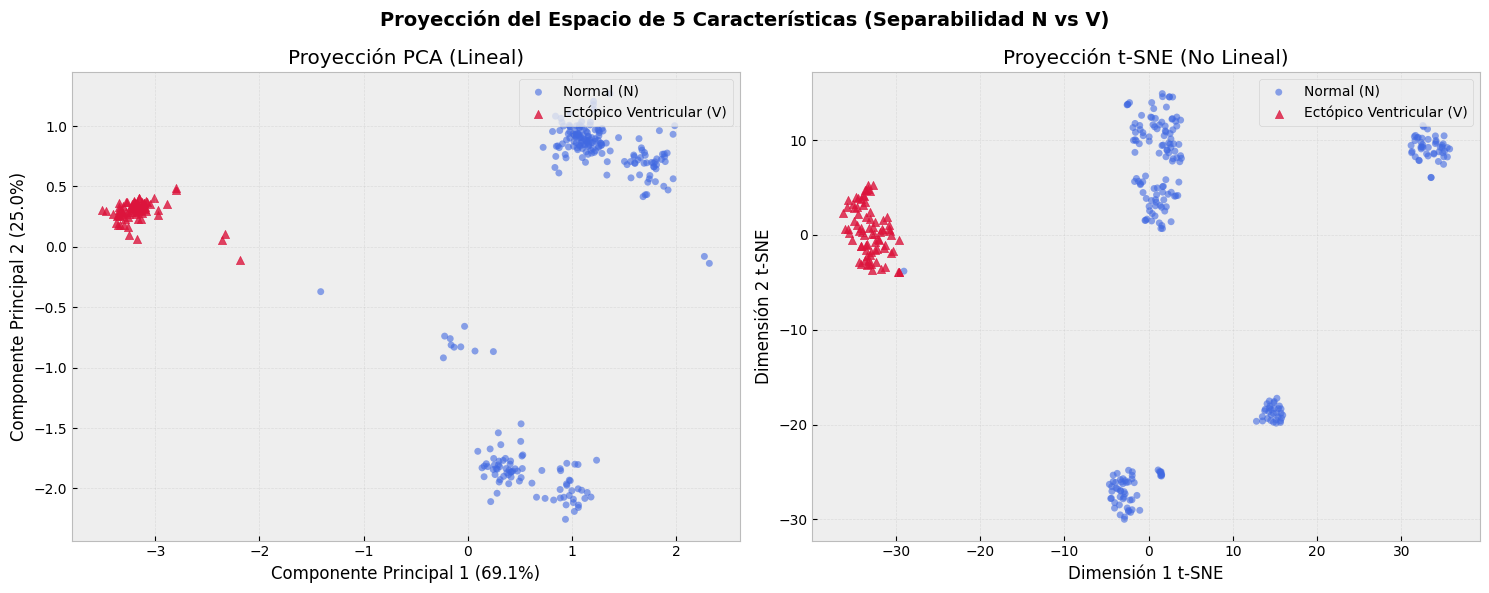

In [16]:
# =============================================================================
# PROYECCIÓN DEL ESPACIO DE CARACTERÍSTICAS (PCA Y t-SNE)
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# 1. Preparación y Escalado de los Datos
# Usamos la matriz 'X' y las etiquetas 'y' que ya fueron extraídas y filtradas del pipeline anterior
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Análisis de Componentes Principales (PCA)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
varianza_explicada = pca.explained_variance_ratio_
varianza_acumulada = np.sum(varianza_explicada) * 100.0

print("=== RESULTADOS DE PCA ===")
print(f"Varianza explicada por CP1: {varianza_explicada[0]*100:.2f}%")
print(f"Varianza explicada por CP2: {varianza_explicada[1]*100:.2f}%")
print(f"Varianza total conservada en 2D: {varianza_acumulada:.2f}%\n")

# 3. Incrustación Estocástica de Vecinos Distribuidos en t (t-SNE)
tsne = TSNE(n_components=2, perplexity=30, random_state=42, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

# 4. Visualización Comparativa en 2D
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Proyección del Espacio de 5 Características (Separabilidad N vs V)', fontsize=14, fontweight='bold')

# Máscaras booleanas para separar las clases en los gráficos
mask_N = (np.array(y) == 'N')
mask_V = (np.array(y) == 'V')

# --- Panel 1: PCA ---
ax1.scatter(X_pca[mask_N, 0], X_pca[mask_N, 1], c='royalblue', label='Normal (N)', alpha=0.6, s=25, edgecolors='none')
ax1.scatter(X_pca[mask_V, 0], X_pca[mask_V, 1], c='crimson', label='Ectópico Ventricular (V)', alpha=0.8, s=35, marker='^')
ax1.set_xlabel(f'Componente Principal 1 ({varianza_explicada[0]*100:.1f}%)')
ax1.set_ylabel(f'Componente Principal 2 ({varianza_explicada[1]*100:.1f}%)')
ax1.set_title('Proyección PCA (Lineal)')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right')

# --- Panel 2: t-SNE ---
ax2.scatter(X_tsne[mask_N, 0], X_tsne[mask_N, 1], c='royalblue', label='Normal (N)', alpha=0.6, s=25, edgecolors='none')
ax2.scatter(X_tsne[mask_V, 0], X_tsne[mask_V, 1], c='crimson', label='Ectópico Ventricular (V)', alpha=0.8, s=35, marker='^')
ax2.set_xlabel('Dimensión 1 t-SNE')
ax2.set_ylabel('Dimensión 2 t-SNE')
ax2.set_title('Proyección t-SNE (No Lineal)')
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()